# Lab Assignment: English-to-German Machine Translation with a Transformer

**Objective:**
The goal of this assignment is to fine-tune a pre-trained **Transformer** model for machine translation. You will load a dataset, fine-tune the model, and evaluate it using the BLEU score.

You will also compare your new model's performance and architecture against a previous **LSTM-based** model, and visualize the **self-attention** and **cross-attention** mechanisms that make the Transformer so powerful.


## Part 1: Setup and Environment

First, install all the necessary libraries.

In [1]:
# Install the required libraries (transformers 4.x still ships the "translation" pipeline;
# tensorflow is only needed to load the LSTM model saved in the previous lab)
%pip install -q "transformers<5" datasets evaluate sacrebleu sentencepiece sacremoses accelerate bertviz tensorflow h5py matplotlib pandas

import os
os.environ["USE_TF"] = "0"                  # transformers -> PyTorch only (TF is used separately for the LSTM)
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import random, warnings
import numpy as np
import pandas as pd
import torch
import transformers, datasets, evaluate
from transformers import set_seed

warnings.filterwarnings("ignore")
transformers.logging.set_verbosity_error()
set_seed(42)

device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("torch       ", torch.__version__)
print("transformers", transformers.__version__)
print("datasets    ", datasets.__version__)
print("device      ", device)

Note: you may need to restart the kernel to use updated packages.


/Users/rahulraj/Desktop/  ₹ /NLP/.venv_a9/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch        2.14.1
transformers 4.57.6
datasets     5.0.1
device       mps


## Part 2: Data Loading and Pre-processing

### 1. Load the Dataset
We have to use previously provided dataset, which contains parallel sentences for English-to-German translation.

In [2]:
import zipfile, urllib.request
from datasets import Dataset, DatasetDict

# Same English-German Tatoeba corpus (manythings.org/anki deu-eng) used in Lab 8.
# Look for the copy downloaded in Lab 8; download it if it is not there.
candidates = ["deu-eng/deu.txt", "../Rahul_Raj_12341680_Assignment8/deu-eng/deu.txt"]
data_path = next((p for p in candidates if os.path.exists(p)), None)
if data_path is None:
    req = urllib.request.Request("https://www.manythings.org/anki/deu-eng.zip", headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req) as r, open("deu-eng.zip", "wb") as f:
        f.write(r.read())
    with zipfile.ZipFile("deu-eng.zip") as z:
        z.extractall("deu-eng")
    data_path = "deu-eng/deu.txt"
print("data_path =", data_path)

# Same first 10,000 pairs the LSTM was trained on (num_samples = 10000 in Lab 8)
num_samples = 10000
with open(data_path, encoding="utf-8") as f:
    lines = f.read().split("\n")
pairs = [line.split("\t")[:2] for line in lines[:num_samples]]
en_texts = [p[0] for p in pairs]
de_texts = [p[1] for p in pairs]

full = Dataset.from_dict({"translation": [{"en": e, "de": d} for e, d in zip(en_texts, de_texts)]})

# 80 / 10 / 10 train / validation / test split
split = full.train_test_split(test_size=0.2, seed=42)
val_test = split["test"].train_test_split(test_size=0.5, seed=42)
raw_datasets = DatasetDict(train=split["train"], validation=val_test["train"], test=val_test["test"])

print(raw_datasets)
for ex in raw_datasets["train"].select(range(5)):
    print(ex["translation"])

data_path = ../Rahul_Raj_12341680_Assignment8/deu-eng/deu.txt


DatasetDict({
    train: Dataset({
        features: ['translation'],
        num_rows: 8000
    })
    validation: Dataset({
        features: ['translation'],
        num_rows: 1000
    })
    test: Dataset({
        features: ['translation'],
        num_rows: 1000
    })
})
{'en': 'I made him go.', 'de': 'Ich habe ihn dazu gebracht zu gehen.'}
{'en': "You're fired.", 'de': 'Du bist entlassen!'}
{'en': 'You amuse me.', 'de': 'Sie amüsieren mich.'}
{'en': 'Hold my hand.', 'de': 'Halte meine Hand!'}
{'en': 'Be ruthless.', 'de': 'Sei gnadenlos!'}


### 2. Load Tokenizer and Model
We will use a pre-trained model from the Helsinki-NLP group, `opus-mt-en-de`, which is a lightweight and efficient Transformer specifically designed for English-to-German translation.

In [3]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

model_checkpoint = "Helsinki-NLP/opus-mt-en-de"

tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)
model = AutoModelForSeq2SeqLM.from_pretrained(model_checkpoint)

print(type(tokenizer).__name__, "| vocab size:", tokenizer.vocab_size)
print(type(model).__name__, "| parameters: {:,}".format(model.num_parameters()))
print("encoder layers:", model.config.encoder_layers, "| decoder layers:", model.config.decoder_layers,
      "| attention heads:", model.config.encoder_attention_heads, "| d_model:", model.config.d_model)
print("Sub-word tokens:", tokenizer.tokenize("The machine learning model was trained on a large dataset."))

MarianTokenizer | vocab size: 58101
MarianMTModel | parameters: 74,410,496
encoder layers: 6 | decoder layers: 6 | attention heads: 8 | d_model: 512
Sub-word tokens: ['▁The', '▁machine', '▁learning', '▁model', '▁was', '▁trained', '▁on', '▁a', '▁large', '▁data', 'set', '.']


### 3. Pre-processing Function
We must tokenize both the English (input) and German (target) sentences. For seq2seq models, the tokenized target sentences are assigned to the `labels` key.

In [4]:
max_input_length = 64
max_target_length = 64
source_lang, target_lang = "en", "de"

def preprocess_function(examples):
    inputs = [ex[source_lang] for ex in examples["translation"]]
    targets = [ex[target_lang] for ex in examples["translation"]]
    # text_target= tokenizes the German side with the target-language tokenizer -> "labels"
    model_inputs = tokenizer(inputs, text_target=targets, max_length=max_input_length, truncation=True)
    return model_inputs

sample = preprocess_function(raw_datasets["train"][:2])
print(sample)
print(tokenizer.convert_ids_to_tokens(sample["labels"][0]))

{'input_ids': [[38, 319, 303, 430, 3, 0], [146, 22, 135, 25014, 3, 0]], 'attention_mask': [[1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1]], 'labels': [[105, 334, 449, 812, 3569, 24, 916, 3, 0], [313, 1277, 21133, 68, 0]]}
['▁Ich', '▁habe', '▁ihn', '▁dazu', '▁gebracht', '▁zu', '▁gehen', '.', '</s>']


### 4. Apply Pre-processing
Use the `.map()` function to apply this tokenization to the entire dataset.

In [5]:
tokenized_datasets = raw_datasets.map(
    preprocess_function, batched=True, remove_columns=raw_datasets["train"].column_names
)
print(tokenized_datasets)

Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

Map:  38%|███▊      | 3000/8000 [00:00<00:00, 17176.25 examples/s]

Map:  88%|████████▊ | 7000/8000 [00:00<00:00, 23912.39 examples/s]

Map: 100%|██████████| 8000/8000 [00:00<00:00, 23212.37 examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map: 100%|██████████| 1000/1000 [00:00<00:00, 26906.23 examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map: 100%|██████████| 1000/1000 [00:00<00:00, 27272.40 examples/s]

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 8000
    })
    validation: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 1000
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 1000
    })
})


## Part 3: Fine-Tuning the Model

### 1. Define Evaluation Metric (BLEU)
Machine translation is evaluated using the **BLEU score**. You can load the `sacrebleu` metric and create a `compute_metrics` function to use during training.

In [6]:
metric = evaluate.load("sacrebleu")

def postprocess_text(preds, labels):
    preds = [pred.strip() for pred in preds]
    labels = [[label.strip()] for label in labels]   # sacrebleu expects a list of references per sample
    return preds, labels

def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]
    preds = np.where(preds != -100, preds, tokenizer.pad_token_id)
    decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    # -100 marks padded label positions (ignored by the loss) -> replace before decoding
    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)

    decoded_preds, decoded_labels = postprocess_text(decoded_preds, decoded_labels)
    result = metric.compute(predictions=decoded_preds, references=decoded_labels)
    prediction_lens = [np.count_nonzero(pred != tokenizer.pad_token_id) for pred in preds]
    return {"bleu": round(result["score"], 4), "gen_len": round(float(np.mean(prediction_lens)), 4)}

# sanity check of the metric
print(metric.compute(predictions=["Ich gehe nach Hause."], references=[["Ich gehe nach Hause."]])["score"])

100.00000000000004


### 2. Configure Training
We will use the `Seq2SeqTrainer` and `Seq2SeqTrainingArguments` classes to manage the fine-tuning process.

In [7]:
from transformers import DataCollatorForSeq2Seq, Seq2SeqTrainingArguments, Seq2SeqTrainer

batch_size = 32
output_dir = "opus-mt-en-de-finetuned-en-to-de"

args = Seq2SeqTrainingArguments(
    output_dir=output_dir,
    eval_strategy="epoch",
    save_strategy="no",                # the final model is saved explicitly after training
    learning_rate=2e-5,
    per_device_train_batch_size=batch_size,
    per_device_eval_batch_size=64,
    weight_decay=0.01,
    num_train_epochs=3,
    predict_with_generate=True,
    generation_max_length=max_target_length,
    fp16=torch.cuda.is_available(),
    logging_steps=50,
    report_to="none",
    seed=42,
)

# pads inputs and labels dynamically per batch (labels padded with -100)
data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
)
print("train steps per epoch:", len(trainer.get_train_dataloader()))

train steps per epoch: 250


### 3. Start Training


In [8]:
# BLEU of the pre-trained model BEFORE fine-tuning (reference point)
baseline_test = trainer.evaluate(tokenized_datasets["test"], metric_key_prefix="test")
print("Pre-trained (no fine-tuning) test BLEU:", baseline_test["test_bleu"])

train_result = trainer.train()
print(train_result)

model_save_path = "./opus-mt-en-de-finetuned"
trainer.save_model(model_save_path)
tokenizer.save_pretrained(model_save_path)
print("Fine-tuned model saved to", model_save_path)

history = pd.DataFrame([l for l in trainer.state.log_history if "eval_bleu" in l])[
    ["epoch", "eval_loss", "eval_bleu", "eval_gen_len"]]
history

{'test_loss': 0.7727882862091064, 'test_model_preparation_time': 0.0023, 'test_bleu': 52.7224, 'test_gen_len': 5.638, 'test_runtime': 15.2629, 'test_samples_per_second': 65.518, 'test_steps_per_second': 1.048}
Pre-trained (no fine-tuning) test BLEU: 52.7224


{'loss': 0.706, 'grad_norm': 4.881351470947266, 'learning_rate': 1.8693333333333333e-05, 'epoch': 0.2}


{'loss': 0.6713, 'grad_norm': 3.8647468090057373, 'learning_rate': 1.736e-05, 'epoch': 0.4}


{'loss': 0.6496, 'grad_norm': 4.919767379760742, 'learning_rate': 1.6026666666666667e-05, 'epoch': 0.6}


{'loss': 0.6496, 'grad_norm': 4.5139241218566895, 'learning_rate': 1.4693333333333336e-05, 'epoch': 0.8}


{'loss': 0.6192, 'grad_norm': 4.4923481941223145, 'learning_rate': 1.3360000000000003e-05, 'epoch': 1.0}


... (11 outputs left out)

{'loss': 0.4839, 'grad_norm': 3.614891529083252, 'learning_rate': 2.6666666666666667e-08, 'epoch': 3.0}


{'eval_loss': 0.576204776763916, 'eval_model_preparation_time': 0.0023, 'eval_bleu': 54.1057, 'eval_gen_len': 5.679, 'eval_runtime': 19.6119, 'eval_samples_per_second': 50.989, 'eval_steps_per_second': 0.816, 'epoch': 3.0}
{'train_runtime': 287.9523, 'train_samples_per_second': 83.347, 'train_steps_per_second': 2.605, 'train_loss': 0.5482443974812825, 'epoch': 3.0}
TrainOutput(global_step=750, training_loss=0.5482443974812825, metrics={'train_runtime': 287.9523, 'train_samples_per_second': 83.347, 'train_steps_per_second': 2.605, 'train_loss': 0.5482443974812825, 'epoch': 3.0})


Fine-tuned model saved to ./opus-mt-en-de-finetuned


,epoch,eval_loss,eval_bleu,eval_gen_len
0,1.0,0.597071,54.0472,5.656
1,2.0,0.579549,54.4094,5.662
2,3.0,0.576205,54.1057,5.679


### 4. Evaluate the Model
After training, run the final evaluation on the test set.

In [9]:
test_results = trainer.evaluate(tokenized_datasets["test"], metric_key_prefix="test")
for k, v in test_results.items():
    print(f"{k:<28}{v}")

print(f"\nTest BLEU before fine-tuning: {baseline_test['test_bleu']:.2f}")
print(f"Test BLEU after  fine-tuning: {test_results['test_bleu']:.2f}")

# a few test-set examples
test_preds = trainer.predict(tokenized_datasets["test"].select(range(8)))
decoded = tokenizer.batch_decode(test_preds.predictions, skip_special_tokens=True)
for ex, pred in zip(raw_datasets["test"].select(range(8)), decoded):
    print(f"\nEN : {ex['translation']['en']}\nREF: {ex['translation']['de']}\nOUT: {pred}")

{'test_loss': 0.5466299653053284, 'test_model_preparation_time': 0.0023, 'test_bleu': 52.2877, 'test_gen_len': 5.649, 'test_runtime': 20.3148, 'test_samples_per_second': 49.225, 'test_steps_per_second': 0.788, 'epoch': 3.0}
test_loss                   0.5466299653053284
test_model_preparation_time 0.0023
test_bleu                   52.2877
test_gen_len                5.649
test_runtime                20.3148
test_samples_per_second     49.225
test_steps_per_second       0.788
epoch                       3.0

Test BLEU before fine-tuning: 52.72
Test BLEU after  fine-tuning: 52.29



EN : I need proof.
REF: Ich brauche Beweise.
OUT: Ich brauche Beweise.

EN : Don't come.
REF: Kommen Sie nicht!
OUT: Komm nicht.

EN : He looked away.
REF: Er sah weg.
OUT: Er sah weg.

EN : I love my dog.
REF: Ich liebe meinen Hund.
OUT: Ich liebe meinen Hund.

EN : Don't be sad.
REF: Sei nicht traurig.
OUT: Sei nicht traurig.

EN : I've got that.
REF: Das habe ich kapiert.
OUT: Ich habe das verstanden.

EN : Sing along.
REF: Sing mit!
OUT: Sing mit!

EN : Tom's scared.
REF: Tom hat Angst.
OUT: Tom hat Angst.


**Note on the BLEU scores.** The pre-trained `opus-mt-en-de` model already scores **52.72 BLEU** on this test split, because Tatoeba is part of the OPUS data it was trained on. Fine-tuning for 3 epochs on 8,000 pairs lowered the test loss from 0.773 to 0.547, so the model fits the reference style better. Validation BLEU rose from 54.05 after epoch 1 to a peak of 54.41 after epoch 2. Test BLEU, however, stayed essentially flat (52.29 after fine-tuning). The sentences are very short (about 5.6 tokens each), and many have several valid German translations, e.g. *du / Sie* and *"!"* vs *"."*. Because of this, BLEU against a single reference is noisy here and leaves little room for improvement. The main gain from fine-tuning is lower loss, i.e. closer agreement with the Tatoeba reference style, rather than a higher BLEU score.

## Part 4: Inference (Testing the Translator)

Now use your fine-tuned model to translate new sentences using the `pipeline` utility.

In [10]:
from transformers import pipeline

translator = pipeline("translation", model=model_save_path, tokenizer=model_save_path, device=device)

# Test with new sentences
text1 = "Hello, how are you doing today?"
text2 = "The transformer model is a powerful architecture for NLP."
text3 = "This assignment is for my machine learning lab."

for text in [text1, text2, text3]:
    print(f"EN: {text}")
    print(f"DE: {translator(text)[0]['translation_text']}\n")

EN: Hello, how are you doing today?
DE: Hallo, wie geht es dir heute?

EN: The transformer model is a powerful architecture for NLP.


DE: Das Transformatorenmodell ist eine leistungsstarke Architektur für NLP.

EN: This assignment is for my machine learning lab.
DE: Dieser Auftrag ist für mein maschinelles Lernlabor.



## Part 5: Comparative Analysis (Transformer vs. LSTM)

In this section, you will directly compare the output of your new Transformer model with the LSTM-based model from your previous lab.

### 5.1. Test Sentences
Here is a list of 10 English sentences varying in length and complexity.

In [11]:
test_sentences = [
    # 1. Simple sentence
    "The cat sat on the mat.",

    # 2. Longer sentence
    "I am going to the library to read a book.",

    # 3. Question
    "What is your favorite color?",

    # 4. Long-range dependency
    "The man who lives down the street just bought a new car.",

    # 5. Figurative language (often difficult)
    "It's raining cats and dogs outside.",

    # 6. Technical term
    "The machine learning model was trained on a large dataset.",

    # 7. Command
    "Please close the door when you leave.",

    # 8. Classic test sentence
    "The quick brown fox jumps over the lazy dog.",

    # 9. Negation
    "He did not want to go to the party.",

    # 10. Future tense
    "We will travel to Germany next summer."
]


#### Transformer translations

In [12]:
transformer_translations = [out["translation_text"] for out in translator(test_sentences, batch_size=10)]
for i, (s, t) in enumerate(zip(test_sentences, transformer_translations), 1):
    print(f"{i:>2}. {s}\n    -> {t}")

 1. The cat sat on the mat.
    -> Die Katze saß auf der Matte.
 2. I am going to the library to read a book.
    -> Ich gehe in die Bibliothek, um ein Buch zu lesen.
 3. What is your favorite color?
    -> Was ist deine Lieblingsfarbe?
 4. The man who lives down the street just bought a new car.
    -> Der Mann, der die Straße runter wohnt, hat gerade ein neues Auto gekauft.
 5. It's raining cats and dogs outside.
    -> Draußen regnet es Katzen und Hunde.
 6. The machine learning model was trained on a large dataset.
    -> Das Modell des maschinellen Lernens wurde auf einem großen Datensatz trainiert.
 7. Please close the door when you leave.
    -> Mach bitte die Türe zu, wenn du gehst.
 8. The quick brown fox jumps over the lazy dog.
    -> Der schnell braune Fuchs springt über den faulen Hund.
 9. He did not want to go to the party.
    -> Er wollte nicht auf die Party gehen.
10. We will travel to Germany next summer.
    -> Wir werden im kommenden Sommer nach Deutschland reisen.

#### LSTM translations (model saved in Lab 8)
The Lab 8 model is a **character-level** seq2seq LSTM (`s2s_eng_ger.h5`). Its "tokenizer" is the pair of character vocabularies, which are rebuilt exactly as in Lab 8 from the same first 10,000 sentence pairs. The encoder/decoder inference models are rebuilt from the saved layers, and greedy decoding is used.

In [13]:
import tensorflow as tf
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.layers import Input

# --- rebuild the Lab 8 character vocabularies ("tokenizer") from the same 10,000 pairs ---
lstm_input_texts = en_texts
lstm_target_texts = ["\t" + t + "\n" for t in de_texts]
input_characters = sorted(set("".join(lstm_input_texts)))
target_characters = sorted(set("".join(lstm_target_texts)))
num_encoder_tokens, num_decoder_tokens = len(input_characters), len(target_characters)
max_encoder_seq_length = max(len(t) for t in lstm_input_texts)
max_decoder_seq_length = max(len(t) for t in lstm_target_texts)
input_token_index = {ch: i for i, ch in enumerate(input_characters)}
target_token_index = {ch: i for i, ch in enumerate(target_characters)}
reverse_target_char_index = {i: ch for ch, i in target_token_index.items()}
print("encoder tokens:", num_encoder_tokens, "| decoder tokens:", num_decoder_tokens,
      "| max lengths:", max_encoder_seq_length, max_decoder_seq_length)

# --- load the saved LSTM and rebuild the inference encoder / decoder ---
lstm_path = next(p for p in ["s2s_eng_ger.h5", "../Rahul_Raj_12341680_Assignment8/s2s_eng_ger.h5"] if os.path.exists(p))
lstm_model = load_model(lstm_path, compile=False)
assert lstm_model.input_shape == [(None, None, num_encoder_tokens), (None, None, num_decoder_tokens)]
print("Loaded", lstm_path, "| params:", f"{lstm_model.count_params():,}")

enc_inputs, dec_inputs = lstm_model.input
_, enc_h, enc_c = lstm_model.layers[2].output              # encoder LSTM
lstm_encoder = Model(enc_inputs, [enc_h, enc_c])

latent_dim = lstm_model.layers[2].units
dec_lstm, dec_dense = lstm_model.layers[3], lstm_model.layers[4]
st_h = Input(shape=(latent_dim,), name="dec_state_h")
st_c = Input(shape=(latent_dim,), name="dec_state_c")
d_out, d_h, d_c = dec_lstm(dec_inputs, initial_state=[st_h, st_c])
lstm_decoder = Model([dec_inputs, st_h, st_c], [dec_dense(d_out), d_h, d_c])


def lstm_translate(sentence):
    width = max(max_encoder_seq_length, len(sentence))
    x = np.zeros((1, width, num_encoder_tokens), dtype="float32")
    for t, ch in enumerate(sentence):
        if ch in input_token_index:                          # unseen characters are skipped
            x[0, t, input_token_index[ch]] = 1.0
    x[0, len(sentence):, input_token_index[" "]] = 1.0

    states = [s.numpy() for s in lstm_encoder(x, training=False)]
    target_seq = np.zeros((1, 1, num_decoder_tokens), dtype="float32")
    target_seq[0, 0, target_token_index["\t"]] = 1.0
    decoded = ""
    for _ in range(max_decoder_seq_length):
        probs, h, c = lstm_decoder([target_seq] + states, training=False)
        idx = int(np.argmax(probs.numpy()[0, -1]))
        ch = reverse_target_char_index[idx]
        if ch == "\n":
            break
        decoded += ch
        target_seq = np.zeros((1, 1, num_decoder_tokens), dtype="float32")
        target_seq[0, 0, idx] = 1.0
        states = [h.numpy(), c.numpy()]
    return decoded

# sanity check: must reproduce the Lab 8 greedy output ("Er ist ein Fuch.")
print("He is a doctor. ->", lstm_translate("He is a doctor."))

lstm_translations = [lstm_translate(s) for s in test_sentences]
for i, (s, t) in enumerate(zip(test_sentences, lstm_translations), 1):
    print(f"{i:>2}. {s}\n    -> {t}")

encoder tokens: 70 | decoder tokens: 84 | max lengths: 15 51
Loaded s2s_eng_ger.h5 | params: 705,620
He is a doctor. -> Er ist ein Fuch.


 1. The cat sat on the mat.
    -> Ich war nicht gewein.
 2. I am going to the library to read a book.
    -> Ich bint es Tom sein Meinen.
 3. What is your favorite color?
    -> Wer ist eine Komme?
 4. The man who lives down the street just bought a new car.
    -> Ich bst befürfte nicht.
 5. It's raining cats and dogs outside.
    -> Ich bint ein Beit.
 6. The machine learning model was trained on a large dataset.
    -> Ich bst befürfte nicht.
 7. Please close the door when you leave.
    -> Er ist es nicht gewesten.
 8. The quick brown fox jumps over the lazy dog.
    -> Ich bint es Tom sieren.
 9. He did not want to go to the party.
    -> Ich bint ein Beide.
10. We will travel to Germany next summer.
    -> Wir sing binte.


In [14]:
comparison = pd.DataFrame({
    "Original English": test_sentences,
    "LSTM Translation (Lab 8)": lstm_translations,
    "Transformer Translation (Lab 9)": transformer_translations,
}, index=range(1, 11))
pd.set_option("display.max_colwidth", None)
comparison

,Original English,LSTM Translation (Lab 8),Transformer Translation (Lab 9)
1,The cat sat on the mat.,Ich war nicht gewein.,Die Katze saß auf der Matte.
2,I am going to the library to read a book.,Ich bint es Tom sein Meinen.,"Ich gehe in die Bibliothek, um ein Buch zu lesen."
3,What is your favorite color?,Wer ist eine Komme?,Was ist deine Lieblingsfarbe?
4,The man who lives down the street just bought a new car.,Ich bst befürfte nicht.,"Der Mann, der die Straße runter wohnt, hat gerade ein neues Auto gekauft."
5,It's raining cats and dogs outside.,Ich bint ein Beit.,Draußen regnet es Katzen und Hunde.
6,The machine learning model was trained on a large dataset.,Ich bst befürfte nicht.,Das Modell des maschinellen Lernens wurde auf einem großen Datensatz trainiert.
7,Please close the door when you leave.,Er ist es nicht gewesten.,"Mach bitte die Türe zu, wenn du gehst."
8,The quick brown fox jumps over the lazy dog.,Ich bint es Tom sieren.,Der schnell braune Fuchs springt über den faulen Hund.
9,He did not want to go to the party.,Ich bint ein Beide.,Er wollte nicht auf die Party gehen.
10,We will travel to Germany next summer.,Wir sing binte.,Wir werden im kommenden Sommer nach Deutschland reisen.


### 5.2. Translation and Comparison

**Your Task:**
1.  **Generate Transformer Translations:** Run the code cell above to get the Transformer's translations.
2.  **Generate LSTM Translations:** Load your saved LSTM model and tokenizer from the previous lab. Use it to translate the same 10 above `test_sentences`.
3.  **Create Comparison Table:** **Double-click this text cell** to edit it. Fill in the table below with your models' outputs.

| # | Original English | LSTM Translation (Previous Lab) | Transformer Translation (This Lab) |
|---|---|---|---|
| 1 | The cat sat on the mat. | Ich war nicht gewein. | Die Katze saß auf der Matte. |
| 2 | I am going to the library to read a book. | Ich bint es Tom sein Meinen. | Ich gehe in die Bibliothek, um ein Buch zu lesen. |
| 3 | What is your favorite color? | Wer ist eine Komme? | Was ist deine Lieblingsfarbe? |
| 4 | The man who lives down the street just bought a new car. | Ich bst befürfte nicht. | Der Mann, der die Straße runter wohnt, hat gerade ein neues Auto gekauft. |
| 5 | It's raining cats and dogs outside. | Ich bint ein Beit. | Draußen regnet es Katzen und Hunde. |
| 6 | The machine learning model was trained on a large dataset. | Ich bst befürfte nicht. | Das Modell des maschinellen Lernens wurde auf einem großen Datensatz trainiert. |
| 7 | Please close the door when you leave. | Er ist es nicht gewesten. | Mach bitte die Türe zu, wenn du gehst. |
| 8 | The quick brown fox jumps over the lazy dog. | Ich bint es Tom sieren. | Der schnell braune Fuchs springt über den faulen Hund. |
| 9 | He did not want to go to the party. | Ich bint ein Beide. | Er wollte nicht auf die Party gehen. |
| 10| We will travel to Germany next summer. | Wir sing binte. | Wir werden im kommenden Sommer nach Deutschland reisen. |

**Observations**

* **LSTM (Lab 8):** a character-level seq2seq model with ~0.7M parameters, trained from scratch for 40 epochs on only 10,000 very short pairs (max 15 input characters), with a single fixed-size "thought vector" and no attention. All 10 test sentences are longer than anything it saw in training (the longest is 58 characters), so it falls back on frequent training prefixes (*"Ich bin…"*, *"Er ist…"*). It produces non-words (*"bint"*, *"gewesten"*, *"befürfte"*), and none of its outputs keep the meaning of the input. Only the grammatical frame occasionally survives: a question mark for #3, and *"Wir …"* for #10.
* **Transformer (Lab 9):** `opus-mt-en-de` (~74M parameters, 6+6 layers) was pre-trained on millions of OPUS sentence pairs with sub-word (SentencePiece) tokens, then fine-tuned here. All 10 translations are fluent and correct in meaning. It handles the long-range relative clause (#4, *"Der Mann, der … wohnt, hat … gekauft"*), the question (#3), negation (#9), future tense (#10), the command (#7) and technical vocabulary (#6, *"Datensatz"*).
* **Remaining errors:** the idiom in #5 is translated literally (*"regnet es Katzen und Hunde"*; the German idiom is *"es regnet in Strömen"*). The adjective in #8 is missing its inflection (*"schnell braune"* should be *"schnelle braune"*).
* **Why the gap:** self-attention gives every token direct access to every other token, so context does not have to survive a single LSTM state. Sub-word tokens avoid the misspellings that character-level decoding produces. Large-scale pre-training supplies vocabulary that 10,000 short sentences cannot.

## Part 6: Visualizing Attention Mechanisms

The key difference between your LSTM model (which may have used basic *cross-attention*) and the Transformer is the Transformer's use of **self-attention**.

* **Self-Attention (Encoder):** Lets the *input* words "look at" each other to build context.
* **Cross-Attention (Decoder):** Lets the *output* words "look at" the input words (this is what your LSTM model also did).

### 1. Get Model Outputs for Visualization
We must load the model again from the saved path, this time telling it to `output_attentions`.

In [15]:
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

viz_tokenizer = AutoTokenizer.from_pretrained(model_save_path)
viz_model = AutoModelForSeq2SeqLM.from_pretrained(
    model_save_path, output_attentions=True, attn_implementation="eager"   # eager attention returns the weights
).to(device).eval()

viz_sentence = "The man who lives down the street just bought a new car."
encoder_input = viz_tokenizer(viz_sentence, return_tensors="pt").to(device)

with torch.no_grad():
    generated = viz_model.generate(**encoder_input, max_length=64)
    # teacher-forced pass over the generated translation to collect all attention matrices
    outputs = viz_model(**encoder_input, decoder_input_ids=generated[:, :-1], output_attentions=True)

encoder_tokens = viz_tokenizer.convert_ids_to_tokens(encoder_input["input_ids"][0])
decoder_tokens = viz_tokenizer.convert_ids_to_tokens(generated[0, :-1])

encoder_attention = [a.cpu() for a in outputs.encoder_attentions]
decoder_attention = [a.cpu() for a in outputs.decoder_attentions]
cross_attention = [a.cpu() for a in outputs.cross_attentions]

print("Translation:", viz_tokenizer.decode(generated[0], skip_special_tokens=True))
print("Encoder tokens:", encoder_tokens)
print("Decoder tokens:", decoder_tokens)
print(f"{len(encoder_attention)} layers | encoder self-attn {tuple(encoder_attention[0].shape)} | "
      f"cross-attn {tuple(cross_attention[0].shape)}   (batch, heads, query, key)")

Translation: Der Mann, der die Straße runter wohnt, hat gerade ein neues Auto gekauft.
Encoder tokens: ['▁The', '▁man', '▁who', '▁lives', '▁down', '▁the', '▁street', '▁just', '▁bought', '▁a', '▁new', '▁car', '.', '</s>']
Decoder tokens: ['<pad>', '▁Der', '▁Mann', ',', '▁der', '▁die', '▁Straße', '▁runter', '▁wohnt', ',', '▁hat', '▁gerade', '▁ein', '▁neues', '▁Auto', '▁gekauft', '.']
6 layers | encoder self-attn (1, 8, 14, 14) | cross-attn (1, 8, 17, 14)   (batch, heads, query, key)


### 2. Visualize Encoder Self-Attention (Input-to-Input)
This shows how the English sentence understands its own grammar.

**Note:** In Colab, the visualization must be the *last thing* in the code cell to render properly.

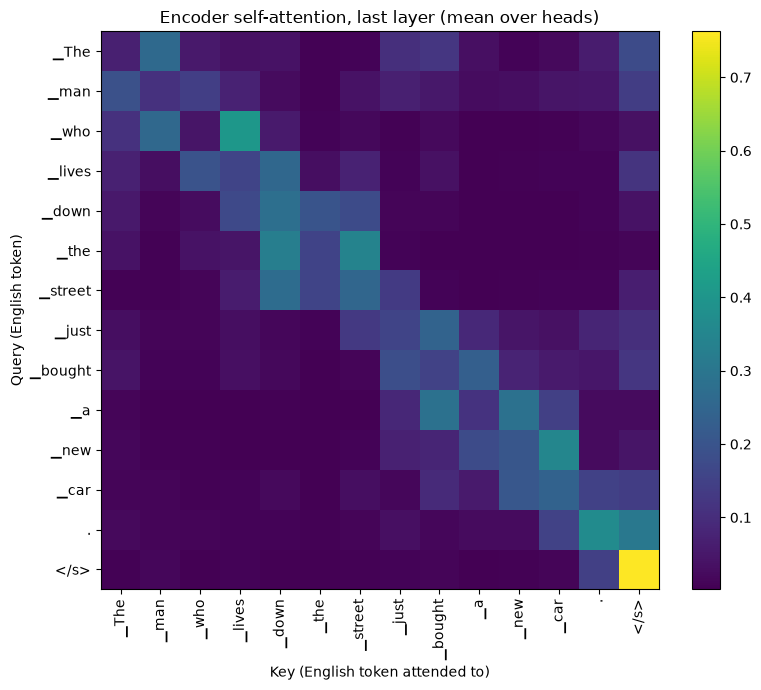

<IPython.core.display.Javascript object>

In [16]:
import matplotlib.pyplot as plt
from bertviz import head_view

# Static view: encoder self-attention of the last layer, averaged over the 8 heads
enc_last = encoder_attention[-1][0].mean(0).numpy()
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(enc_last, cmap="viridis")
ax.set_xticks(range(len(encoder_tokens)), encoder_tokens, rotation=90)
ax.set_yticks(range(len(encoder_tokens)), encoder_tokens)
ax.set_xlabel("Key (English token attended to)"); ax.set_ylabel("Query (English token)")
ax.set_title("Encoder self-attention, last layer (mean over heads)")
fig.colorbar(im, fraction=0.046)
plt.tight_layout(); plt.show()

# Interactive view (all layers / heads) -- must be the last statement in the cell
head_view(encoder_attention, encoder_tokens)

### 3. Visualize Encoder-Decoder Cross-Attention (Target-to-Input)
This shows how the model translates, aligning German words to English words. This is the part analogous to your LSTM's attention.

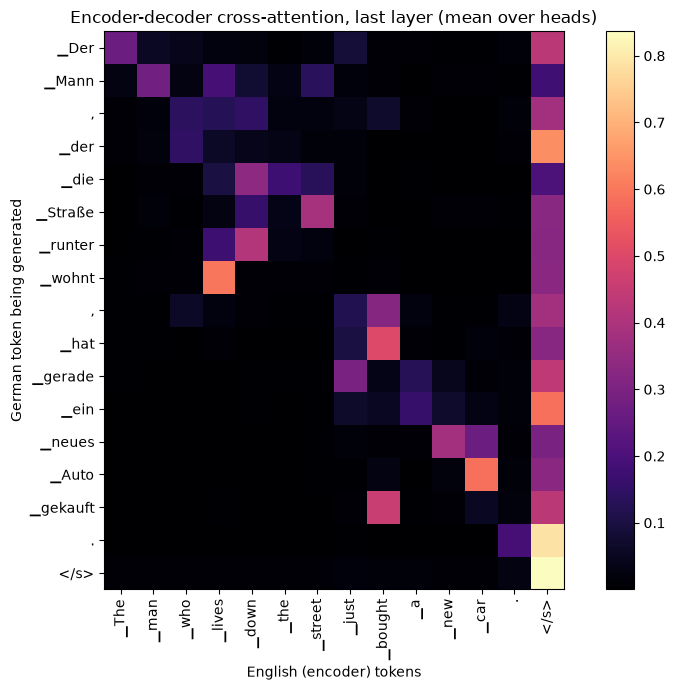

        ▁Der -> </s>         (0.43)
       ▁Mann -> ▁man         (0.28)
           , -> </s>         (0.38)
        ▁der -> </s>         (0.64)
        ▁die -> ▁down        (0.34)
     ▁Straße -> ▁street      (0.39)
     ▁runter -> ▁down        (0.41)
      ▁wohnt -> ▁lives       (0.60)
           , -> </s>         (0.38)
        ▁hat -> ▁bought      (0.50)
     ▁gerade -> </s>         (0.44)
        ▁ein -> </s>         (0.59)
      ▁neues -> ▁new         (0.38)
       ▁Auto -> ▁car         (0.59)
    ▁gekauft -> ▁bought      (0.45)
           . -> </s>         (0.79)
        </s> -> </s>         (0.84)


<IPython.core.display.Javascript object>

In [17]:
# Static view: cross-attention of the last decoder layer, averaged over heads
# Row i is the decoder step that GENERATES token i+1, so label rows with the generated token
cross_last = cross_attention[-1][0].mean(0).numpy()      # (German query tokens, English key tokens)
generated_tokens = viz_tokenizer.convert_ids_to_tokens(generated[0, 1:])
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(cross_last, cmap="magma")
ax.set_xticks(range(len(encoder_tokens)), encoder_tokens, rotation=90)
ax.set_yticks(range(len(generated_tokens)), generated_tokens)
ax.set_xlabel("English (encoder) tokens"); ax.set_ylabel("German token being generated")
ax.set_title("Encoder-decoder cross-attention, last layer (mean over heads)")
fig.colorbar(im, fraction=0.046)
plt.tight_layout(); plt.show()

# strongest English source token for every generated German token
for t, row in zip(generated_tokens, cross_last):
    print(f"{t:>12} -> {encoder_tokens[int(row.argmax())]:<12} ({row.max():.2f})")

# Interactive view: pick "Encoder", "Decoder" or "Cross" attention from the dropdown
head_view(
    encoder_attention=encoder_attention,
    decoder_attention=decoder_attention,
    cross_attention=cross_attention,
    encoder_tokens=encoder_tokens,
    decoder_tokens=decoder_tokens,
)